# 00 · The minimal physical system (Bunin & Rivoire), re-implemented

This notebook rebuilds the engine that every later notebook relies on, and checks it against the
main results of *Evolutionary features in a minimal physical system* (arXiv:2411.03843).

**The model.**  $N$ catalysed reactions $A_iA_i' \to A_i + A_i'$ (catalyst $C_i$). The product $A_i$
inhibits the catalysts of a few other reactions, reciprocally (a sparse random-regular graph, $c=3$);
inhibition is ultrasensitive because $A_i$ must first saturate a binder $B_i$. After coarse-graining
(paper App. B) and adding demographic noise (App. C) and diffusion (App. D):

$$\partial_t A_i = \frac{\Lambda_i}{1+\Gamma\sum_{j\sim i}\max(0,A_j-B_j)} - \delta A_i
  + \omega\sqrt{c_i+\delta A_i}\,\xi_i + D\,\Delta A_i + \text{(diffusion noise)}$$

Stable states are the maximal independent sets of the inhibition graph. Noise drives rare jumps
between them ("mutations"), biased toward states with more active species ("productivity" $P$).

| Paper result | Section below |
|---|---|
| Bistable switching, Fig. 1G / S1 | 1 |
| Number of stable states $\sim e^{0.26N}$, Fig. S7 | 2 |
| Directional increase of $P$, well-mixed, Fig. S5 | 3 |
| Spatial expansion = reproduction, fewer states over time, Fig. 2 | 4 |
| Competition favours the more productive state, Fig. 4 | 5 |
| Adaptation to the environment $\vec\Lambda$, Fig. 5 | 6 |

Run time on a laptop: ~6–8 min (set `FAST = True` for ~3 min).

In [1]:
import os, time, numpy as np, matplotlib.pyplot as plt, networkx as nx
from protoevo import Chem, Links, ancestral_state, productivity, similarity
os.makedirs('figures', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FAST = False
t_start = time.time()

## 1 · A four-node network: bistability and noise-driven switching (Fig. 1C–D, Fig. S1)
Graph of Fig. 1C: node 2 inhibits 1, 3, 4, and 3–4 inhibit each other. Its stable states are
{2} ($P=0.25$), {1,3} and {1,4} ($P=0.5$). Starting in {2}, noise moves the system into the
high-productivity pair and it then hops between {1,3} and {1,4}.

stable states: [[1, 0, 1, 0], [1, 0, 0, 1], [0, 1, 0, 0]]


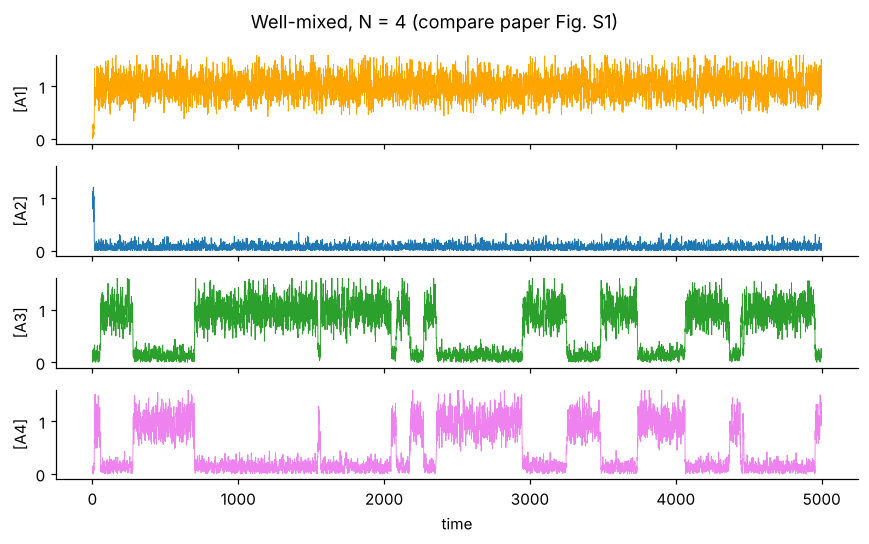

In [2]:
G4 = nx.Graph([(0, 1), (1, 2), (1, 3), (2, 3)])          # nodes 1..4 of the paper -> 0..3
chem4 = Chem(graph=G4, omega=0.2)
print('stable states:', chem4.enumerate_states().tolist())
rng = np.random.default_rng(1)
X = np.array([[0.05, 1.0, 0.05, 0.05]])                  # start in state {2}
X, traj = chem4.run(X, 5000, rng, record_every=50)
fig, ax = plt.subplots(4, 1, figsize=(8, 5), sharex=True)
t = np.arange(len(traj)) * 50 * chem4.dt
for i, c in enumerate(['orange', 'tab:blue', 'tab:green', 'violet']):
    ax[i].plot(t, traj[:, 0, i], c=c, lw=0.6); ax[i].set_ylabel(f'[A{i+1}]'); ax[i].set_ylim(-0.1, 1.6)
ax[-1].set_xlabel('time'); fig.suptitle('Well-mixed, N = 4 (compare paper Fig. S1)'); plt.tight_layout()
plt.savefig('figures/00_fig_S1.png'); plt.show()

## 2 · How many stable states? (Fig. S7)
Exhaustive enumeration (Bron–Kerbosch on the complement graph) for random-regular graphs, $c=3$.

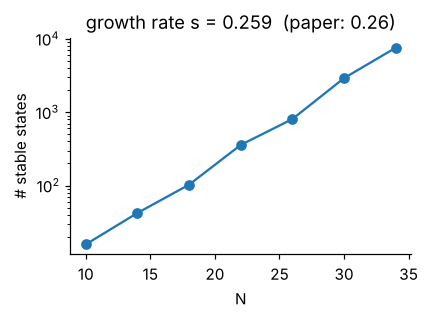

In [3]:
Ns = [10, 14, 18, 22, 26, 30] if FAST else [10, 14, 18, 22, 26, 30, 34]
counts = []
for N in Ns:
    counts.append(np.mean([len(Chem(N=N, seed=s).enumerate_states()) for s in range(4)]))
s_fit = np.polyfit(Ns, np.log(counts), 1)[0]
plt.figure(figsize=(4, 3)); plt.semilogy(Ns, counts, 'o-'); plt.xlabel('N'); plt.ylabel('# stable states')
plt.title(f'growth rate s = {s_fit:.3f}  (paper: 0.26)'); plt.tight_layout()
plt.savefig('figures/00_fig_S7.png'); plt.show()

## 3 · Directionality in a well-mixed reactor (Fig. S5A)
$N=50$, many independent replicates simulated at once. Productivity of the nearest stable state
rises over time, with no Lyapunov function: transitions that *deactivate* fewer species are
exponentially more likely (App. E), so the jump process drifts toward states with more active species.

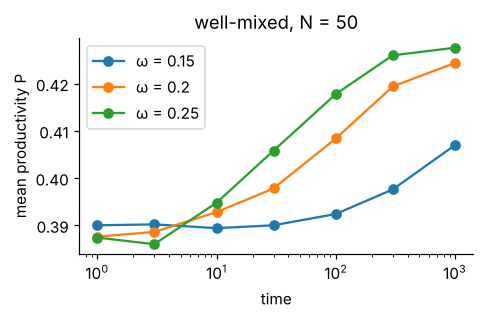

In [4]:
chem = Chem(N=50, seed=11)
R = 60 if FAST else 100
T_wm = [1, 3, 10, 30, 100, 300] + ([] if FAST else [1000])
res = {}
for om in [0.15, 0.2, 0.25]:
    rng = np.random.default_rng(0); X = np.zeros((R, 50)); tp = 0; P = []
    for T in T_wm:
        X = chem.run(X, T - tp, rng, omega=om); tp = T
        P.append(productivity(chem.stable_state(X)).mean())
    res[om] = P
plt.figure(figsize=(4.5, 3))
for om, P in res.items(): plt.semilogx(T_wm, P, 'o-', label=f'ω = {om}')
plt.xlabel('time'); plt.ylabel('mean productivity P'); plt.legend(); plt.title('well-mixed, N = 50')
plt.tight_layout(); plt.savefig('figures/00_fig_S5.png'); plt.show()

## 4 · Space: expansion of states is a form of reproduction (Fig. 2)
One-dimensional periodic tube, $M=100$ cells, $D=1$, $\omega=0.1$ per cell. Starting from all-zero,
many states nucleate, then the more productive ones invade their neighbours: productivity rises and
the number of distinct states falls. (The paper runs to $T=10^5$; we stop at $10^3$ to stay on a laptop.)

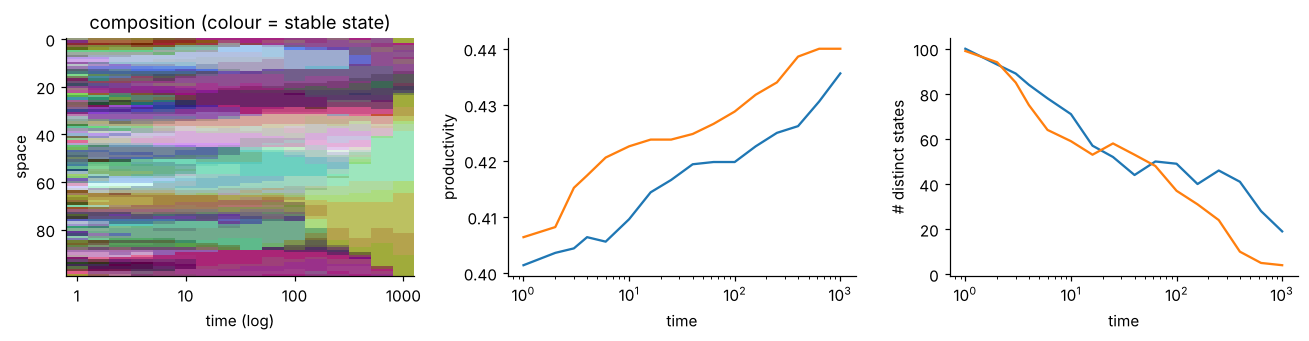

In [5]:
R, M = (2, 100)
T_sp = list(np.unique(np.logspace(0, 2.5 if FAST else 3, 16).round().astype(int)))
rng = np.random.default_rng(2); L = Links.ring(M, R)
X = np.zeros((M * R, 50)); tp = 0; kymo = []; Psp, Nst = [], []
for T in T_sp:
    X = chem.run(X, T - tp, rng, links=L, D=1.0); tp = T
    S = chem.stable_state(X).reshape(R, M, 50)
    Psp.append(S.mean(axis=(1, 2)))
    Nst.append([len(np.unique(S[r], axis=0)) for r in range(R)])
    kymo.append(S[0])
# colour each cell by its stable state, using a fixed random projection of the 50-dim state onto RGB
proj = np.random.default_rng(5).random((50, 3))
img = np.array([(k @ proj) for k in kymo]); img = (img - img.min()) / (img.max() - img.min())
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].imshow(img.transpose(1, 0, 2), aspect='auto', interpolation='nearest')
tick = [i for i, t in enumerate(T_sp) if t in (1, 10, 100, 1000)]
ax[0].set_xticks(tick); ax[0].set_xticklabels([T_sp[i] for i in tick]); ax[0].set_xlabel('time (log)'); ax[0].set_ylabel('space')
ax[0].set_title('composition (colour = stable state)')
ax[1].semilogx(T_sp, np.array(Psp)); ax[1].set_xlabel('time'); ax[1].set_ylabel('productivity')
ax[2].semilogx(T_sp, np.array(Nst)); ax[2].set_xlabel('time'); ax[2].set_ylabel('# distinct states')
plt.tight_layout(); plt.savefig('figures/00_fig_2.png'); plt.show()

## 5 · Competition between evolved states (Fig. 3–4)
Evolve many short trajectories ($M=10$, $T=100$) from the all-zero state; juxtapose two final
compositions (5 cells each) and let them compete for $T=100$. The outcome is usually closest to the
more productive competitor: productivity behaves like fitness.

distinct evolved states: 188 / 200
competition won (closer) by the more productive state in 96% of unequal pairs


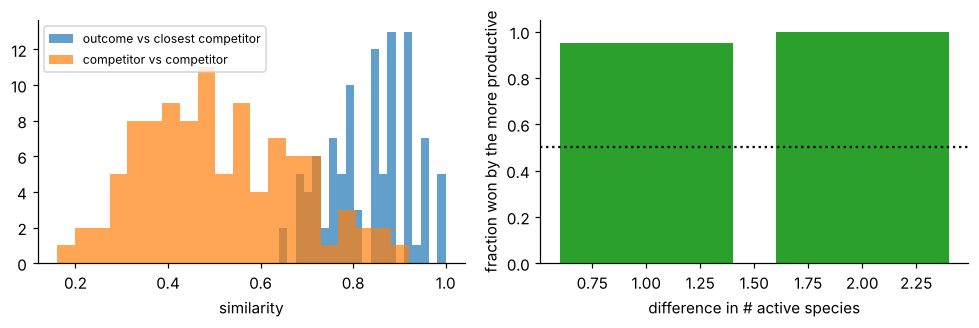

In [6]:
def evolve_systems(chem, R, M, T, rng, Lam=1.0, X0=None):
    L = Links.ring(M, R)
    X = np.zeros((R * M, chem.N)) if X0 is None else X0
    X = chem.run(X, T, rng, links=L, D=1.0, Lam=Lam)
    return X.reshape(R, M, chem.N)

def median_state(chem, Xsys, Lam=1.0):
    S = chem.stable_state(Xsys.reshape(-1, chem.N), Lam=Lam).reshape(Xsys.shape)
    return (S.mean(1) > 0.5).astype(np.int8)

R = 120 if FAST else 200
rng = np.random.default_rng(3)
Xev = evolve_systems(chem, R, 10, 100, rng)
Sev = median_state(chem, Xev)
Pev = productivity(Sev)
pairs = rng.choice(R, size=(R // 2, 2), replace=False)
X0 = np.concatenate([np.concatenate([Xev[a, :5], Xev[b, :5]]) for a, b in pairs])
Xc = evolve_systems(chem, len(pairs), 10, 100, rng, X0=X0)
Sc = median_state(chem, Xc)
s1 = similarity(Sc, Sev[pairs[:, 0]]); s2 = similarity(Sc, Sev[pairs[:, 1]])
dP = Pev[pairs[:, 0]] - Pev[pairs[:, 1]]
closer_to_fitter = np.where(dP > 0, s1 > s2, s2 > s1)[dP != 0]
print(f'distinct evolved states: {len(np.unique(Sev, axis=0))} / {R}')
print(f'competition won (closer) by the more productive state in {closer_to_fitter.mean():.0%} of unequal pairs')
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(np.maximum(s1, s2), bins=20, alpha=.7, label='outcome vs closest competitor')
ax[0].hist(similarity(Sev[pairs[:, 0]], Sev[pairs[:, 1]]), bins=20, alpha=.7, label='competitor vs competitor')
ax[0].set_xlabel('similarity'); ax[0].legend(fontsize=8)
dk = np.round(np.abs(dP[dP != 0]) * chem.N).astype(int)      # difference in # active species
ks = [k for k in range(1, 5) if np.sum(dk == k) >= 3]
ax[1].bar(ks, [closer_to_fitter[dk == k].mean() for k in ks], color='tab:green')
ax[1].set_ylim(0, 1.05); ax[1].axhline(0.5, ls=':', c='k')
ax[1].set_xlabel('difference in # active species'); ax[1].set_ylabel('fraction won by the more productive')
plt.tight_layout(); plt.savefig('figures/00_fig_4.png'); plt.show()

## 6 · Environments and adaptation (Fig. 5)
An environment is the vector of substrate supplies $\vec\Lambda$. Evolve systems in $\vec\Lambda^{(1)}$
and $\vec\Lambda^{(2)}$ (entries uniform in [0,1]); compete one of each in $\vec\Lambda^{(1)}$.

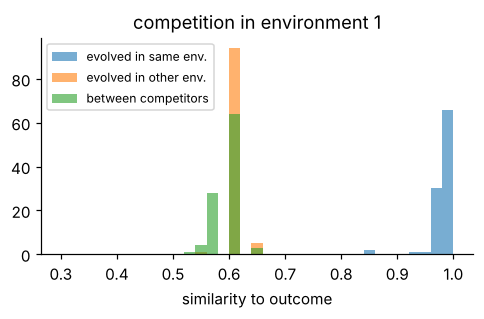

total run time: 705 s


In [7]:
rng = np.random.default_rng(4)
L1, L2 = rng.random(50), rng.random(50)
R = 60 if FAST else 100
X1 = evolve_systems(chem, R, 10, 100, rng, Lam=L1); S1 = median_state(chem, X1, L1)
X2 = evolve_systems(chem, R, 10, 100, rng, Lam=L2); S2 = median_state(chem, X2, L2)
X0 = np.concatenate([np.concatenate([X1[i, :5], X2[i, :5]]) for i in range(R)])
Xc = evolve_systems(chem, R, 10, 100, rng, Lam=L1, X0=X0); Sc = median_state(chem, Xc, L1)
plt.figure(figsize=(4.5, 3))
for s, lab in [(similarity(Sc, S1), 'evolved in same env.'), (similarity(Sc, S2), 'evolved in other env.'),
               (similarity(S1, S2), 'between competitors')]:
    plt.hist(s, bins=np.linspace(0.3, 1.0, 36), alpha=.6, label=lab)
plt.xlabel('similarity to outcome'); plt.legend(fontsize=8); plt.title('competition in environment 1')
plt.tight_layout(); plt.savefig('figures/00_fig_5.png'); plt.show()
print(f'total run time: {time.time() - t_start:.0f} s')

## What carries forward
* A **stable state** is a heritable composition: a "genotype" written in concentrations, not in a template.
* **Mutations** are noise-driven state switches; their supply is set by $\omega$ (compartment volume).
* **Directionality**: switches are biased toward higher productivity.
* **Diffusion between compartments** makes linked compartments share, and propagate, a state.

Notebooks 01–03 put these chemistries inside *cells* that grow, divide, stay attached, fracture and are
selected, and ask whether the three challenges of the multicellularity review can be met.